In [1]:
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sb
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from tqdm import tqdm

/Users/attila/Library/Python/3.12/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [1]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

/Users/attila/Library/Python/3.12/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
vul = pd.read_csv("data/vulnerabilities.csv.gz")
exploitSignals = pd.read_csv("data/exploit_signals_2024.csv.gz")
exploitSignals2 = pd.read_csv("data/exploit_signals_2025.csv.gz")
knownExploits = pd.read_csv("data/known_exploited.csv.gz")
scoreBoard = pd.read_csv("data/scoreboard_2026.csv.gz")
weaknesses = pd.read_csv("data/weakness_types.csv.gz")
ref = pd.read_csv("data/references.csv.gz") 
affects = pd.read_csv("data/affected_products.csv.gz")

/var/folders/bz/6qk9ds4s1q52wqc85m4jh_qr0000gn/T/ipykernel_83925/725422424.py:8: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  affects = pd.read_csv("data/affected_products.csv.gz")


In [3]:
VulDetails = vul[vul['cvss3_score'] > 9.0].sort_values(by='cvss3_score', ascending=False).head(10)
VulDetails = VulDetails[['cve_id', 'cvss3_score', 'description']]
print (VulDetails)

                cve_id  cvss3_score  \
267571  CVE-2024-49668         10.0   
352037  CVE-2026-46798         10.0   
371820  CVE-2026-74705         10.0   
329298  CVE-2026-14812         10.0   
159660  CVE-2021-21960         10.0   
137068   CVE-2020-1889         10.0   
371913  CVE-2026-74843         10.0   
329094  CVE-2026-14560         10.0   
79766    CVE-2016-1044         10.0   
352082  CVE-2026-46846         10.0   

                                              description  
267571  Unrestricted Upload of File with Dangerous Typ...  
352037  Vulnerability in the Oracle WebCenter Sites pr...  
371820  In the Linux kernel, the following vulnerabili...  
329298  The Premium SEO WordPress plugin is malicious:...  
159660  A stack-based buffer overflow vulnerability ex...  
137068  A security feature bypass issue in WhatsApp De...  
371913  A vulnerability was determined in Wavlink WN53...  
329094  The teddy-bear-customize-addon WordPress plugi...  
79766   Adobe Reader and Acrob

In [5]:
model_id = "ibm-granite/granite-4.0-micro" 
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype="auto").to(device)
model.eval()

def ask(prompt, max_new_tokens=150):
    chat = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

W1107 17:34:00.036000 83639 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 322/322 [00:00<00:00, 5493.03it/s]


In [ ]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

model_id = "ibm-granite/granite-4.0-micro" 
#idk

# Check for CUDA (NVIDIA), MPS (Apple Silicon), or fallback to CPU
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

tokenizer = AutoTokenizer.from_pretrained(model_id)

# Load model and move it to your M1 Pro GPU (mps)
model = AutoModelForCausalLM.from_pretrained(
    model_id, 
    torch_dtype=torch.float16 if device == "mps" else "auto"
).to(device)
model.eval()

def ask(prompt, max_new_tokens=150):
    chat = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(device)
    
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

Using device: mps


Loading weights: 100%|██████████| 322/322 [00:07<00:00, 41.82it/s]


In [7]:
VulDetails = vul[vul['cvss3_score'] > 9.0].sort_values(by='cvss3_score', ascending=False).head(10)
VulDetails = VulDetails[['cve_id', 'cvss3_score', 'description']].copy()

def summarize_cve(desc):
    prompt = (
        "Summarize this vulnerability description in one plain-English sentence. "
        "State what is affected, what an attacker can do, and any key condition. "
        "Do not add information that is not in the text.\n\n"
        f"Description: {desc}"
    )
    return ask(prompt, max_new_tokens=80)

VulDetails['summary'] = VulDetails['description'].apply(summarize_cve)
print(VulDetails[['cve_id', 'cvss3_score', 'summary']].to_string(index=False))

        cve_id  cvss3_score                                                                                                                                                                                                                                                                                                                                                        summary
CVE-2024-49668         10.0                                                                                                                                                 This vulnerability allows an attacker to upload a web shell to a web server, potentially gaining unauthorized access and control, affecting the Verbalize WP plugin version 1.0 and possibly earlier versions.
CVE-2026-46798         10.0                                                                                                                                      An unauthenticated attacker with network access can exploit a vulnerability in Or

In [8]:
import numpy as np
import pandas as pd
import torch
from tsfm_public.models.tinytimemixer import TinyTimeMixerForPrediction

MODEL = "ibm-granite/granite-timeseries-ttm-r2"
REVISION = "90-30-ft-l1-r2.1"  # context 90 weeks -> forecast 30 weeks
CTX, PRED = 90, 30
DATA = "data/"
TOP_N = 8                       # number of CWE channels (+ "total" and "other")
START, END = "2022-04-03", "2025-12-28"
FUTURE_WEEKS = 60               # 2 rolls of 30 weeks


def weekly_matrix() -> pd.DataFrame:
    """Loads compressed KEV data (.csv.gz) and builds a weekly count matrix."""
    kev_path = DATA + "known_exploited.csv.gz"
    kev = pd.read_csv(kev_path, parse_dates=["date_added"])
    weeks = pd.date_range(START, END, freq="W-SUN")

    def weekly(s):
        return s.groupby(pd.Grouper(freq="W-SUN")).size().reindex(weeks, fill_value=0.0)

    kev = kev[kev.date_added >= pd.Timestamp(START) - pd.Timedelta(days=6)]
    cols = {"total": weekly(kev.set_index("date_added").cve_id)}

    # Extract top CWE categories
    ex = kev.assign(cwe=kev.cwe_ids.fillna("").str.split(";")).explode("cwe")
    ex = ex[ex.cwe.str.startswith("CWE-", na=False)]
    top = ex.cwe.value_counts().head(TOP_N).index.tolist()

    for cwe in top:
        cols[cwe] = weekly(ex[ex.cwe == cwe].set_index("date_added").cve_id)
    
    cols["other"] = (cols["total"] - sum(cols[c] for c in top)).clip(lower=0)
    return pd.DataFrame(cols)


def forecast(model, past: np.ndarray) -> np.ndarray:
    """Scales context, runs model inference, and restores scale (clipped at 0)."""
    mu, sd = past.mean(0), past.std(0) + 1e-6
    x = torch.tensor(((past - mu) / sd)[None], dtype=torch.float32)
    
    with torch.no_grad():
        y = model(past_values=x).prediction_outputs[0].numpy()
        
    return np.clip(y * sd + mu, 0, None)


def main():
    model = TinyTimeMixerForPrediction.from_pretrained(MODEL, revision=REVISION).eval()
    df = weekly_matrix()
    vals, idx = df.values, df.index
    print(f"{len(df)} weeks, channels: {list(df.columns)}")

    rows, ttm_err, naive_err = [], [], []

    # 1) Walk-forward backtest
    for t in range(CTX, len(df), PRED):
        past = vals[t - CTX:t]
        f = forecast(model, past)[: len(df) - t]
        naive = np.tile(past[-26:].mean(0), (len(f), 1))  # trailing 26-week mean baseline
        actual = vals[t:t + len(f)]

        ttm_err.append(np.abs(f - actual))
        naive_err.append(np.abs(naive - actual))

        for i in range(len(f)):
            for j, ch in enumerate(df.columns):
                rows.append((idx[t + i], ch, f[i, j], naive[i, j], "walkforward"))

    ttm_mae = np.concatenate(ttm_err).mean(0)
    naive_mae = np.concatenate(naive_err).mean(0)
    
    print("\nBacktest MAE per channel (lower is better):")
    print(pd.DataFrame({"ttm": ttm_mae, "naive_26wk": naive_mae}, index=df.columns).round(3))
    print(f"Overall Mean MAE: TTM {ttm_mae.mean():.3f} vs Naive {naive_mae.mean():.3f}")

    # 2) Future rolling forecast
    hist = vals[-CTX:].copy()
    fut_out = []
    
    for _ in range(FUTURE_WEEKS // PRED):
        f = forecast(model, hist[-CTX:])
        fut_out.append(f)
        hist = np.vstack([hist, f])
        
    fut = np.vstack(fut_out)
    naive_fut = np.tile(vals[-26:].mean(0), (len(fut), 1))
    fut_idx = pd.date_range(idx[-1] + pd.Timedelta(weeks=1), periods=len(fut), freq="W-SUN")

    for i in range(len(fut)):
        for j, ch in enumerate(df.columns):
            rows.append((fut_idx[i], ch, fut[i, j], naive_fut[i, j], "future"))

    pd.DataFrame(rows, columns=["week_end", "channel", "ttm_rate", "naive_rate", "source"]) \
      .to_csv("ttm_cwe_pressure.csv", index=False)
    print("\nWrote results to ttm_cwe_pressure.csv")


In [9]:
import pandas as pd

DATA_DIR = "data/"

# Load core datasets
vul = pd.read_csv(DATA_DIR + "vulnerabilities.csv.gz")
knownExploits = pd.read_csv(DATA_DIR + "known_exploited.csv.gz")
weaknesses = pd.read_csv(DATA_DIR + "weakness_types.csv.gz")

# Combine exploit signals across years (if they share a consistent structure)
exploit_signals_24_25 = pd.concat([
    pd.read_csv(DATA_DIR + "exploit_signals_2024.csv.gz"),
    pd.read_csv(DATA_DIR + "exploit_signals_2025.csv.gz")
], ignore_index=True)

# Example join: Enrich vulnerabilities with CISA KEV status
vul_enriched = vul.merge(
    knownExploits[['cve_id', 'date_added']].rename(columns={'date_added': 'kev_date_added'}), 
    on='cve_id', 
    how='left'
)

# Flag whether a vulnerability is actively exploited in KEV
vul_enriched['is_kev'] = vul_enriched['kev_date_added'].notna()

print(f"Loaded {len(vul):,} total vulnerabilities. KEV matches: {vul_enriched['is_kev'].sum():,}")

Loaded 401,082 total vulnerabilities. KEV matches: 1,484


In [7]:
# Setup device (Fallback to CPU if MPS crashes)
if torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(f"Using device: {device}")

# 1. Load data and filter top 1,000 critical vulnerabilities (> 9.0 CVSS)
vul = pd.read_csv("data/vulnerabilities.csv.gz")
VulDetails = vul[vul['cvss3_score'] > 9.0].sort_values(by='cvss3_score', ascending=False).head(150)
VulDetails = VulDetails[['cve_id', 'cvss3_score', 'description']].copy()

print(f"Loaded {len(VulDetails)} high-severity vulnerabilities for summarization.")

# 2. Load Local Granite Model
model_id = "ibm-granite/granite-4.0-micro" 
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(
    model_id, 
    torch_dtype=torch.float16 if device == "mps" else "auto"
).to(device)
model.eval()

def ask(prompt, max_new_tokens=100):
    chat = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def summarize_cve(desc):
    # Handle missing or empty descriptions gracefully
    if pd.isna(desc) or not isinstance(desc, str) or len(desc.strip() ) == 0:
        return "No description provided."
    prompt = (
        "Summarize this vulnerability description in one plain-English sentence. "
        "State what is affected, what an attacker can do, and any key condition. "
        "Do not add information that is not in the text.\n\n"
        f"Description: {desc}"
    )
    return ask(prompt, max_new_tokens=80)

# 3. Process descriptions with a progress bar
summaries = []
print("Generating summaries using local LLM...")
for desc in tqdm(VulDetails['description']):
    summaries.append(summarize_cve(desc))

VulDetails['summary'] = summaries

# Save results to CSV so you don't have to rerun the LLM loop again
VulDetails.to_csv("top_1000_vuln_summaries.csv", index=False)
print("Saved outputs to top_1000_vuln_summaries.csv")

# Print top 5 rows preview
print("\nPreview of top results:")
print(VulDetails[['cve_id', 'cvss3_score', 'summary']].head(5).to_string(index=False))

Using device: mps
Loaded 150 high-severity vulnerabilities for summarization.


Loading weights: 100%|██████████| 322/322 [00:09<00:00, 35.08it/s]


Generating summaries using local LLM...


100%|██████████| 150/150 [06:52<00:00,  2.75s/it]

Saved outputs to top_1000_vuln_summaries.csv

Preview of top results:
        cve_id  cvss3_score                                                                                                                                                                                                                                                                                                       summary
CVE-2024-49668         10.0                                                                                                This vulnerability allows an attacker to upload a web shell to a web server, potentially gaining unauthorized access and control, affecting the Verbalize WP plugin version 1.0 and possibly earlier versions.
CVE-2026-46798         10.0                                                                                     An unauthenticated attacker with network access can exploit a vulnerability in Oracle WebCenter Sites, potentially leading to takeover of the system, with a h

In [11]:

# 1. Load your core vulnerabilities file
# vul = pd.read_csv("data/vulnerabilities.csv.gz")

# # 2. Filter top 1,000 critical vulnerabilities (> 9.0 CVSS)
# VulDetails = vul[vul['cvss3_score'] > 9.0].sort_values(by='cvss3_score', ascending=False).head(1000)

# # 3. Select only the columns you want
# VulDetails = VulDetails[['cve_id', 'cvss3_score', 'description']]

# 4. Save to its own CSV file
VulDetails.to_csv("top_150_vulnerabilities.csv", index=False)

print(f"Successfully saved {len(VulDetails)} vulnerabilities to 'top_150_vulnerabilities.csv'!")

Successfully saved 1000 vulnerabilities to 'top_150_vulnerabilities.csv'!


Loading datasets...


/var/folders/bz/6qk9ds4s1q52wqc85m4jh_qr0000gn/T/ipykernel_83925/1763881907.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  VulDetails['is_actively_exploited'] = VulDetails['is_actively_exploited'].fillna(False)
/var/folders/bz/6qk9ds4s1q52wqc85m4jh_qr0000gn/T/ipykernel_83925/1763881907.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_vendors.values, y=top_vendors.index, ax=axes[0], palette="Blues_r")
/var/folders/bz/6qk9ds4s1q52wqc85m4jh_qr0000gn/T/ipykernel_83925/1763881907.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variab

Saved enriched data to 'enriched_top_1000_vulnerabilities.csv'


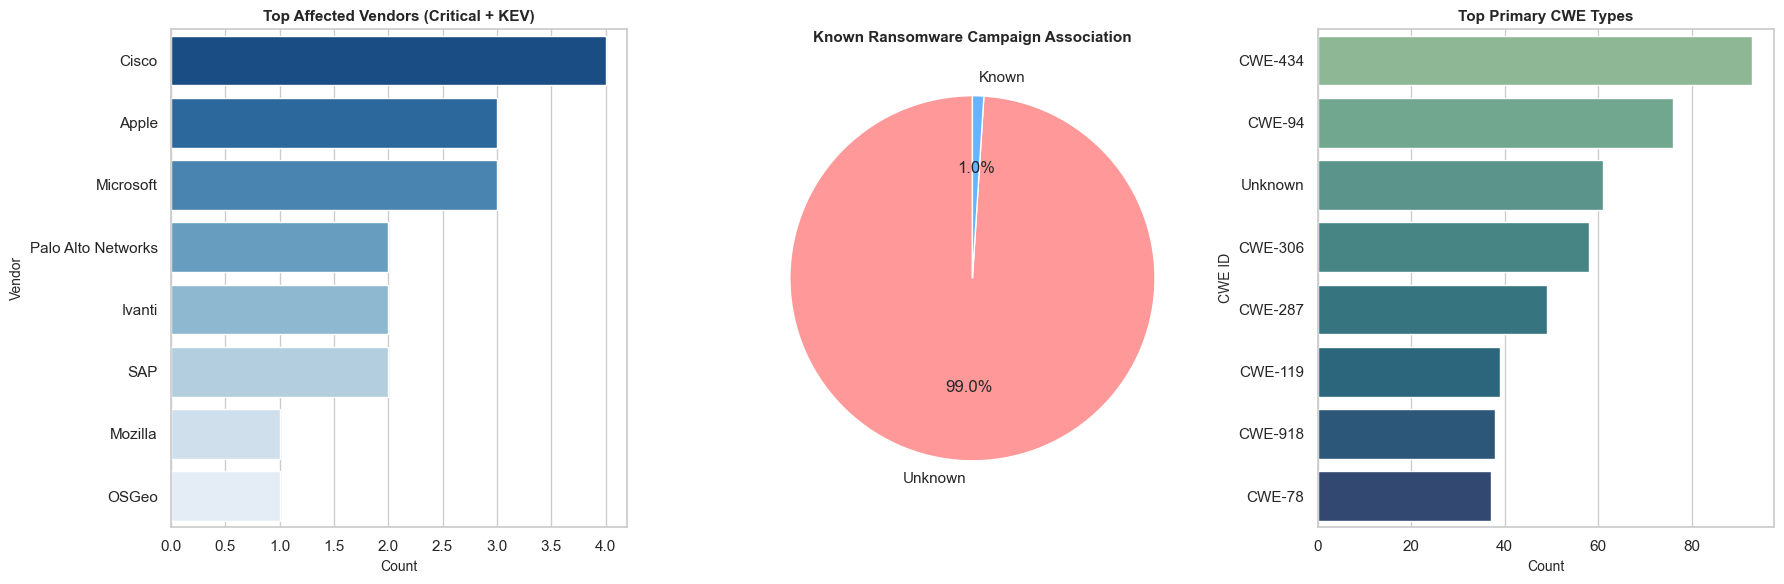

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme
sns.set_theme(style="whitegrid")

print("Loading datasets...")
# 1. Load core datasets with correct filenames & KEV headers
vul = pd.read_csv("data/vulnerabilities.csv.gz")
kev = pd.read_csv("data/known_exploited.csv.gz", parse_dates=["date_added"])

# 2. Filter top 1,000 critical vulnerabilities (> 9.0 CVSS)
VulDetails = vul[vul['cvss3_score'] > 9.0].sort_values(by='cvss3_score', ascending=False).head(1000).copy()

# 3. Merge with KEV catalog using your exact headers
# KEV headers: cve_id, vendor, product, name, date_added, short_description, required_action, due_date, known_ransomware_use, cwe_ids
kev_subset = kev[['cve_id', 'vendor', 'product', 'date_added', 'known_ransomware_use']].copy()
kev_subset['is_actively_exploited'] = True

# Merge into our vulnerability details
VulDetails = VulDetails.merge(kev_subset, on='cve_id', how='left')
VulDetails['is_actively_exploited'] = VulDetails['is_actively_exploited'].fillna(False)

# Clean up ransomware column (usually marked 'Known' or similar in CISA KEV, or boolean/string)
VulDetails['known_ransomware_use'] = VulDetails['known_ransomware_use'].fillna('Unknown')

# 4. Extract primary CWE from cwe_ids
def get_primary_cwe(cwe_val):
    if pd.isna(cwe_val) or not isinstance(cwe_val, str):
        return "Unknown"
    first_cwe = cwe_val.split(';')[0].strip()
    return first_cwe if first_cwe.startswith("CWE-") else "Unknown"

VulDetails['primary_cwe'] = VulDetails['cwe_ids'].apply(get_primary_cwe)

# Save enriched dataset
VulDetails.to_csv("enriched_top_1000_vulnerabilities.csv", index=False)
print("Saved enriched data to 'enriched_top_1000_vulnerabilities.csv'")

# ==========================================
# 5. CREATE A 3-PANEL DASHBOARD VISUALIZATION
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- Panel 1: Top 8 Vulnerability Vendors in KEV ---
top_vendors = VulDetails['vendor'].dropna().value_counts().head(8)
sns.barplot(x=top_vendors.values, y=top_vendors.index, ax=axes[0], palette="Blues_r")
axes[0].set_title("Top Affected Vendors (Critical + KEV)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Count", fontsize=10)
axes[0].set_ylabel("Vendor", fontsize=10)

# --- Panel 2: Known Ransomware Association ---
ransomware_counts = VulDetails['known_ransomware_use'].value_counts()
axes[1].pie(
    ransomware_counts, 
    labels=ransomware_counts.index, 
    autopct='%1.1f%%', 
    colors=['#ff9999','#66b3ff','#99ff99'], 
    startangle=90
)
axes[1].set_title("Known Ransomware Campaign Association", fontsize=11, fontweight='bold')

# --- Panel 3: Top Root Weaknesses (CWEs) ---
top_cwes = VulDetails['primary_cwe'].value_counts().head(8)
sns.barplot(x=top_cwes.values, y=top_cwes.index, ax=axes[2], palette="crest")
axes[2].set_title("Top Primary CWE Types", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Count", fontsize=10)
axes[2].set_ylabel("CWE ID", fontsize=10)

plt.tight_layout()
plt.show()